# Lab 1.3 — Calidad de datos, sesgo y desbalance

**Curso:** AWS Certified Machine Learning Engineer – Associate (MLA-C02) · **Tema:** 1.3

Reproduce localmente lo que hacen AWS Glue Data Quality, DataBrew o Data Wrangler y SageMaker Clarify:

1. Validar datos con reglas al estilo DQDL.
2. Limpiar sin *data leakage*.
3. Medir el sesgo pre-training (CI y DPL).
4. Tratar el desbalance de clases.

No requiere cuenta de AWS ni credenciales.

## 0. Preparación

Los módulos reutilizables están en `src/`.

In [1]:
import sys

sys.path.insert(0, "src")

In [2]:
from pathlib import Path

import pandas as pd

import bias
import clean
import imbalance
import plots
import quality
from generate_data import generate

LANG = "es"
RULES = Path("rules.dqdl")
pd.set_option("display.width", 120)

## 1. Datos crudos

10.150 solicitudes de préstamo sintéticas generadas con semilla fija. Incluyen a propósito duplicados, edades inválidas, `income` faltante y extremo, un 8–9 % de impagos y mayores de 60 subrepresentados.

In [3]:
raw = generate()
Path("data").mkdir(exist_ok=True)
raw.to_csv("data/loans_raw.csv", index=False)
print(f"rows={len(raw):,}  default rate={raw['default'].mean():.1%}  missing income={raw['income'].isna().mean():.1%}")
raw.head()

rows=10,150  default rate=8.6%  missing income=8.9%


,application_id,age,income,loan_amount,credit_history_years,debt_ratio,default
0,APP-000621,43,35579.0,3625.0,19,0.506,0
1,APP-004385,29,47064.0,11639.0,2,0.355,0
2,APP-006794,57,63567.0,25914.0,38,0.216,0
3,APP-004562,35,27522.0,12656.0,17,0.353,0
4,APP-009264,25,32689.0,19345.0,5,0.571,0


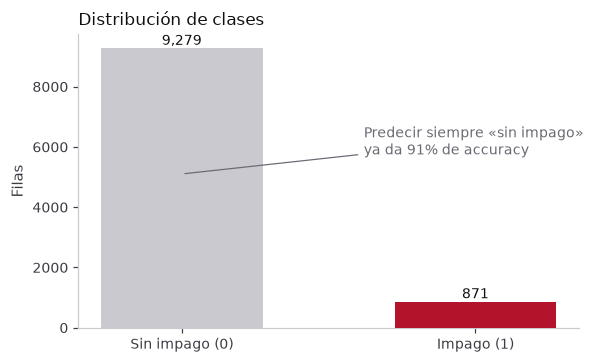

In [4]:
plots.class_distribution(raw, LANG);

Con tan pocos positivos, un modelo que siempre predice «sin impago» ya logra una *accuracy* alta. Por eso la *accuracy* sola es engañosa.

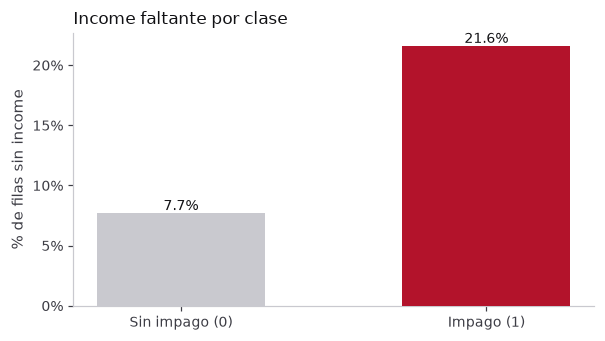

In [5]:
plots.missing_by_class(raw, LANG);

Los impagos tienen más `income` faltante: la ausencia del dato **es información**. Por eso, al imputar, conviene añadir una columna indicadora.

## 2. Validar la calidad (equivalente a Glue Data Quality)

`rules.dqdl` usa la sintaxis de DQDL. `quality.py` evalúa un subconjunto de reglas y calcula el *score*: el porcentaje de reglas que se cumplen.

In [6]:
print(RULES.read_text())

Rules = [
  IsComplete "application_id",
  IsUnique "application_id",
  ColumnValues "age" between 18 and 100,
  Completeness "income" > 0.85,
  ColumnValues "default" in [0, 1],
  RowCount > 5000
]



In [7]:
score, results = quality.evaluate(raw, RULES)
quality.print_report("Raw data", score, results)


Raw data  —  data quality score: 67%
  [PASS] IsComplete "application_id"                   0 nulls
  [FAIL] IsUnique "application_id"                     150 duplicated values
  [FAIL] ColumnValues "age" between 18 and 100         15 values out of range
  [PASS] Completeness "income" > 0.85                  completeness = 0.911
  [PASS] ColumnValues "default" in [0, 1]              0 values not allowed
  [PASS] RowCount > 5000                               10150 rows


> En un trabajo de Glue ETL, el transform *Evaluate Data Quality* puede **detener el trabajo** antes de cargar los datos cuando una regla falla.

## 3. Limpiar sin *data leakage*

1. Eliminar duplicados y registros inválidos.
2. Dividir en entrenamiento y prueba con **estratificación** y mezcla.
3. Calcular la mediana y los límites IQR **solo con el entrenamiento**.
4. Imputar, añadir `income_missing` y recortar outliers en ambos conjuntos.

In [8]:
valid = clean.drop_invalid(raw)
train, test = clean.split(valid)
stats = clean.fit_cleaning(train)  # solo entrenamiento / training split only
train, test = clean.apply_cleaning(train, stats), clean.apply_cleaning(test, stats)

print(f"{len(raw):,} -> {len(valid):,} rows after removing duplicates and invalid ages")
print(f"income median={stats['median']:,.0f}  IQR bounds=[{stats['low']:,.0f}, {stats['high']:,.0f}]")
print(f"default rate  train={train['default'].mean():.2%}  test={test['default'].mean():.2%}")

10,150 -> 9,985 rows after removing duplicates and invalid ages
income median=40,810  IQR bounds=[-14,073, 100,467]
default rate  train=8.64%  test=8.61%


In [9]:
score, results = quality.evaluate(pd.concat([train, test]), RULES)
quality.print_report("Clean data", score, results)


Clean data  —  data quality score: 100%
  [PASS] IsComplete "application_id"                   0 nulls
  [PASS] IsUnique "application_id"                     0 duplicated values
  [PASS] ColumnValues "age" between 18 and 100         0 values out of range
  [PASS] Completeness "income" > 0.85                  completeness = 1.000
  [PASS] ColumnValues "default" in [0, 1]              0 values not allowed
  [PASS] RowCount > 5000                               9985 rows


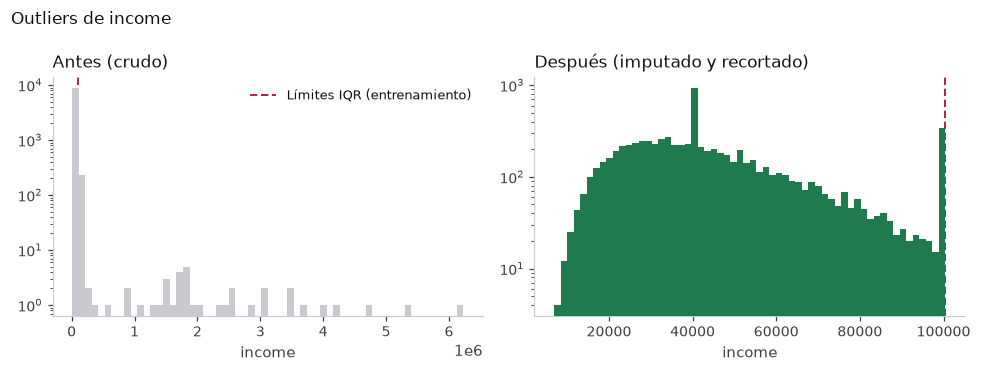

In [10]:
plots.income_before_after(raw, train, stats, LANG);

Recortar a los límites IQR conserva las filas y reduce la influencia de los extremos. Es el equivalente a `REPLACE_OUTLIERS` en DataBrew o a *Handle outliers* en Data Wrangler.

## 4. Sesgo pre-training (definiciones de SageMaker Clarify)

Faceta **d** = mayores de 60; faceta **a** = el resto.

- **CI** = (nₐ − n_d) / (nₐ + n_d): ¿está **subrepresentada** la faceta d? (0 = equilibrio)
- **DPL** = qₐ − q_d: ¿recibe una faceta **más etiquetas positivas**? (0 = paridad)

Ninguna de las dos necesita un modelo.

In [11]:
facet_d = valid["age"] > 60
report = bias.report(valid, facet_d, "default")
pd.Series(report).round(3)

n_a    8582.000
n_d    1403.000
q_a       0.081
q_d       0.122
CI        0.719
DPL      -0.041
dtype: float64

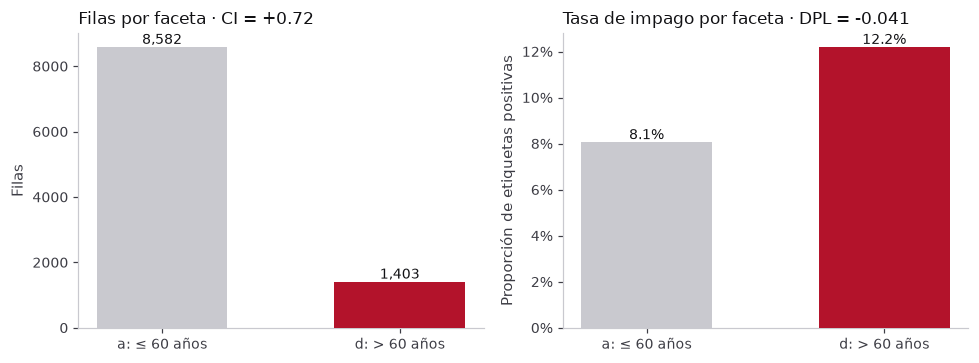

In [12]:
plots.facets(valid, facet_d, report, LANG);

CI > 0 indica que la faceta d está subrepresentada. DPL < 0 indica que la faceta d tiene una mayor proporción de impagos en los datos. Antes de entrenar, documenta el hallazgo y busca más datos del grupo d.

## 5. Desbalance de clases

Se compara la línea base con `scale_pos_weight ≈ negativos / positivos` y con SMOTE (**solo en entrenamiento**). El conjunto de prueba **no se remuestrea**: debe reflejar los datos reales.

In [13]:
metrics, predictions = imbalance.compare(train, test)
metrics

,accuracy,balanced_acc,recall,f1,roc_auc
always 'no default',0.914,0.500,0.000,0.000,0.500
xgboost baseline,0.915,0.530,0.064,0.115,0.720
scale_pos_weight=10.6,0.732,0.656,0.564,0.266,0.709
SMOTE (train only),0.688,0.637,0.576,0.241,0.696


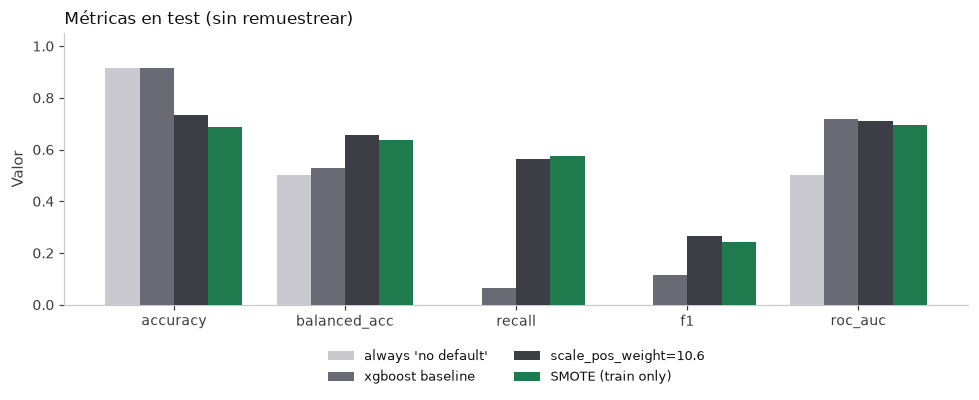

In [14]:
plots.metrics_comparison(metrics, LANG);

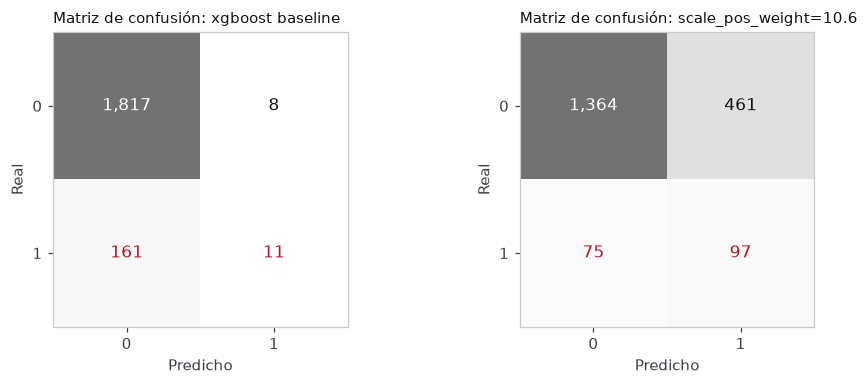

In [15]:
names = [n for n in predictions if n.startswith(("xgboost", "scale_pos_weight"))]
plots.confusion_matrices(test["default"], predictions, names, LANG);

La línea base casi no detecta impagos (*recall* bajo). Ponderar o remuestrear sacrifica *accuracy* para subir el *recall* y el F1: esas son las métricas que importan al negocio.

## 6. Equivalencia en AWS

| Este laboratorio | En AWS | Diferencias principales |
|---|---|---|
| `quality.py` + `rules.dqdl` | AWS Glue Data Quality (*Evaluate Data Quality*) | Glue admite muchas más reglas, reglas dinámicas, detección de anomalías, recomendaciones y métricas en CloudWatch. |
| `clean.py` | AWS Glue DataBrew o SageMaker Data Wrangler | Herramientas visuales con recetas o flujos reutilizables que escalan. |
| `bias.py` | Métricas pre-training de SageMaker Clarify | Clarify ya no acepta clientes nuevos; AWS recomienda calcularlas con pandas, como aquí. |
| `imbalance.py` | XGBoost integrado de SageMaker AI, *Balance data* de Data Wrangler | Entrenamiento en instancias gestionadas y ajuste automático con `validation:f1` o `validation:auc`. |

### Prueba esto

- Cambia `Completeness "income" > 0.85` por `> 0.95` en `rules.dqdl` y vuelve a ejecutar.
- Aplica SMOTE **antes** de dividir los datos y observa cómo se inflan las métricas de prueba.
- Cambia la faceta a `age < 25` y compara CI y DPL.